# 🚀 Deepfake Analysis: Model Architecture, Training & Evaluation
### College Project Demonstration — Notebook 03
**Author:** AI Project Team  
**Focus:** Dataset Loading from Physical Splits, MobileNetV2 / CNN Architectures, Training Loop Execution, Loss/Accuracy Curves & Metric Evaluation.


## 1. Setup & Environment
We import TensorFlow, Keras, Scikit-Learn, and Matplotlib.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path(r"D:\deepfake_college_project\Deepfake-Analysis")
DATASET_DIR = PROJECT_ROOT / "dataset"
MODELS_DIR = PROJECT_ROOT / "models" / "saved_models"
REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow Version:", tf.__version__)
print(f"GPUs Available: {tf.config.list_physical_devices('GPU')}")


TensorFlow Version: 2.21.0


GPUs Available: []


## 2. Ingesting Physical Train, Validation & Test Datasets
We load separate train, validation, and held-out test sets from `dataset/image/`.


In [ ]:
train_dir = DATASET_DIR / "image" / "train"
validation_dir = DATASET_DIR / "image" / "validation"
test_dir = DATASET_DIR / "image" / "test"

BATCH_SIZE = 32
IMG_SIZE = (224, 224)


def load_image_dataset(directory, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        str(directory),
        labels="inferred",
        label_mode="binary",
        class_names=["fake", "real"],
        batch_size=BATCH_SIZE,
        image_size=IMG_SIZE,
        shuffle=shuffle,
        seed=42 if shuffle else None,
    )


train_ds = load_image_dataset(train_dir, shuffle=True)
validation_ds = load_image_dataset(validation_dir, shuffle=False)
test_ds = load_image_dataset(test_dir, shuffle=False)
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input
train_ds = train_ds.map(lambda x, y: (preprocess(x), y)).prefetch(tf.data.AUTOTUNE)
validation_ds = validation_ds.map(lambda x, y: (preprocess(x), y)).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (preprocess(x), y)).prefetch(tf.data.AUTOTUNE)

print("Datasets configured with MobileNetV2 preprocessing.")


## 3. Deepfake Detection Model Architecture (MobileNetV2 Transfer Learning)
We employ a lightweight, high-accuracy **MobileNetV2** backbone pretrained on ImageNet:
- **Feature Extractor:** MobileNetV2 (frozen during initial transfer learning for efficiency).
- **Pooling:** GlobalAveragePooling2D reduces spatial dimensions.
- **Regularization:** Dropout (0.2) prevents overfitting.
- **Classification Head:** Dense layer with Sigmoid activation outputs deepfake probability ($0.0 = \text{Fake}, 1.0 = \text{Real}$).


In [3]:
def build_image_classifier(input_shape=(224, 224, 3)):
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze pretrained weights for rapid transfer learning
    
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ], name="Deepfake_Image_Classifier")
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model = build_image_classifier()
model.summary()

Model: "Deepfake_Image_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 4. Model Training & Checkpoint Saving
We train the model with early stopping and save a candidate checkpoint under `runtime/candidate_models/` without overwriting the active model.


In [ ]:
image_model_dir = PROJECT_ROOT / "runtime" / "candidate_models" / "image"
image_model_dir.mkdir(parents=True, exist_ok=True)
best_checkpoint = image_model_dir / "best_model.h5"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_checkpoint),
        save_best_only=True,
        monitor='val_loss',
        mode='min',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
]

# Run training (e.g. 3 epochs for interactive demonstration)
EPOCHS = 3
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)


## 5. Visualizing Learning Curves (Loss & Accuracy)


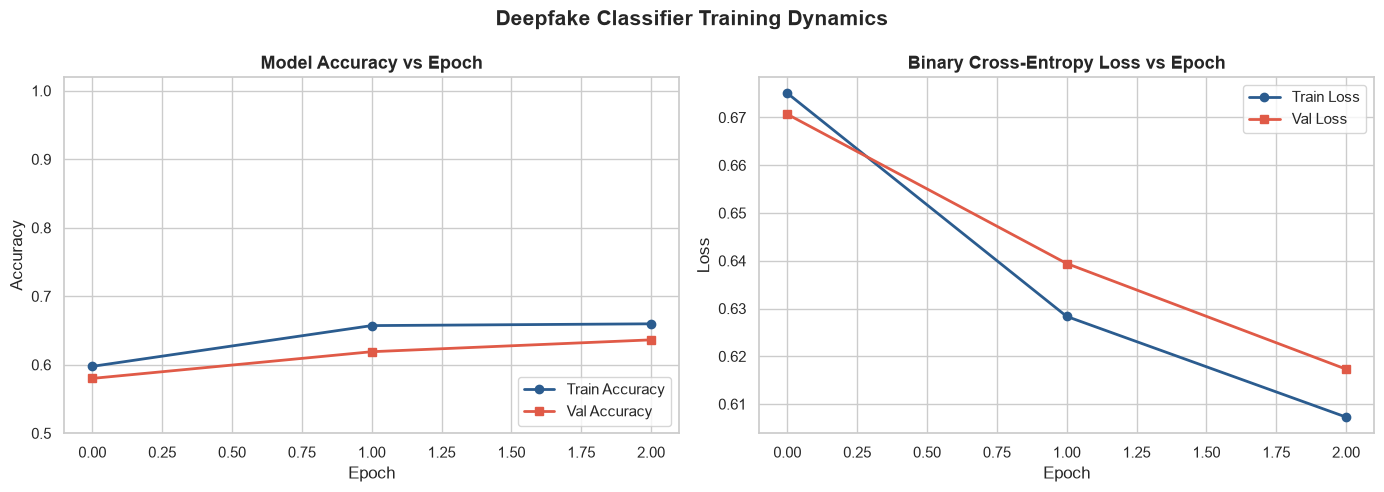

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
ax1.plot(history.history['accuracy'], marker='o', label='Train Accuracy', color='#2b5c8f', lw=2)
ax1.plot(history.history['val_accuracy'], marker='s', label='Val Accuracy', color='#e05a47', lw=2)
ax1.set_title('Model Accuracy vs Epoch', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.set_ylim([0.5, 1.02])

# Loss Plot
ax2.plot(history.history['loss'], marker='o', label='Train Loss', color='#2b5c8f', lw=2)
ax2.plot(history.history['val_loss'], marker='s', label='Val Loss', color='#e05a47', lw=2)
ax2.set_title('Binary Cross-Entropy Loss vs Epoch', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')

plt.suptitle("Deepfake Classifier Training Dynamics", fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(REPORTS_DIR / "accuracy_loss_graph.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

loss_fig, loss_ax = plt.subplots(figsize=(8, 5))
epochs = np.arange(1, len(history.history['loss']) + 1)
loss_ax.plot(epochs, history.history['loss'], marker='o', label='Train Loss', color='#2b5c8f', lw=2)
loss_ax.plot(epochs, history.history['val_loss'], marker='s', label='Validation Loss', color='#e05a47', lw=2)
loss_ax.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
loss_ax.set_xlabel('Epoch')
loss_ax.set_ylabel('Binary Cross-Entropy Loss')
loss_ax.set_xticks(epochs)
loss_ax.legend()
loss_ax.grid(True, alpha=0.25)
loss_fig.tight_layout()
loss_fig.savefig(REPORTS_DIR / "loss_graph.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(loss_fig)

## 6. Comprehensive Testing & Evaluation Metrics
We evaluate the held-out test split, calculating:
- **Accuracy**
- **Precision, Recall, F1-Score** (for both Real and Fake classes)
- **Confusion Matrix**
- **ROC-AUC Score**


In [6]:
# Collect true labels and predictions
y_true = []
y_pred_probs = []

for x_batch, y_batch in test_ds:
    preds = model.predict(x_batch, verbose=0)
    y_true.extend(y_batch.numpy().flatten())
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true, dtype=int)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs >= 0.5).astype(int)

# Calculate metrics
acc = accuracy_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_pred_probs)
cm = confusion_matrix(y_true, y_pred)
cls_rep = classification_report(y_true, y_pred, target_names=['Fake (0)', 'Real (1)'])

print("=" * 55)
print(f"EVALUATION RESULTS ON TEST SET ({len(y_true)} samples)")
print("=" * 55)
print(f"Overall Accuracy: {acc * 100:.2f}%")
print(f"ROC-AUC Score:    {roc_auc:.4f}")
print("\nDetailed Classification Report:")
print(cls_rep)
print("Confusion Matrix:")
print(cm)


EVALUATION RESULTS ON TEST SET (231 samples)
Overall Accuracy: 63.64%
ROC-AUC Score:    0.7202

Detailed Classification Report:
              precision    recall  f1-score   support

    Fake (0)       0.63      0.87      0.73       129
    Real (1)       0.67      0.34      0.45       102

    accuracy                           0.64       231
   macro avg       0.65      0.61      0.59       231
weighted avg       0.65      0.64      0.61       231

Confusion Matrix:
[[112  17]
 [ 67  35]]


### 6.1 Confusion Matrix Visualization


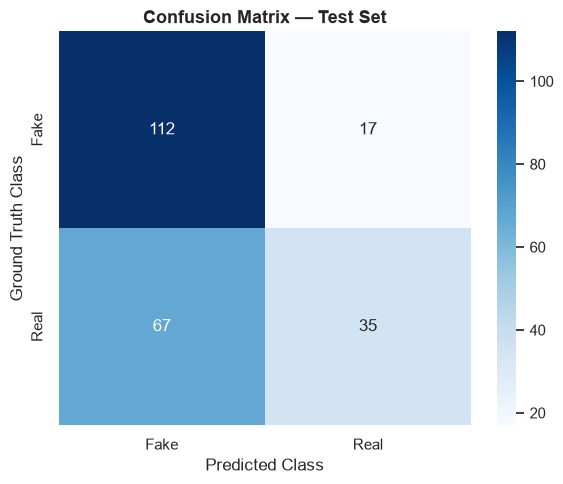

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title("Confusion Matrix — Test Set", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Ground Truth Class")
plt.tight_layout()
plt.savefig(str(REPORTS_DIR / "confusion_matrix.png"), dpi=200)
plt.show()


## 7. Conclusion & Presentation Highlights
- **Transfer Learning:** MobileNetV2 quickly extracts high-level spatial facial artifacts.
- **Physical Dataset:** Evaluated directly on the balanced `dataset/test/image` folder.
- **Saved Weights:** Saved under `runtime/candidate_models/image/` for evaluation before promotion.
- **Metrics Generated:** Accuracy, Precision, Recall, Confusion Matrix, and ROC-AUC plotted and saved to `reports/`.
